In [ ]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

PROCESSED_DIR = Path("../data/processed")

files = sorted(
    PROCESSED_DIR.glob(
        "yellow_tripdata_*_clean.parquet"
    )
)

samples = []

for file in files:

    df = pd.read_parquet(
        file,
        columns=[
            "trip_distance",
            "trip_duration_minutes",
            "avg_speed_mph",
            "fare_amount",
            "tip_amount",
            "total_amount",
            "revenue_per_mile",
            "revenue_per_minute",
            "tip_percentage",
            "pickup_hour",
            "pickup_weekday_num",
            "is_weekend",
            "is_rush_hour",
            "payment_type",
            "pickup_borough",
            "pickup_zone",
            "valid_tip_analysis",
            "valid_revenue_efficiency",
        ]
    )

    samples.append(
        df.sample(
            n=min(100_000, len(df)),
            random_state=42
        )
    )

analysis_df = pd.concat(
    samples,
    ignore_index=True
)

analysis_df.shape

Matplotlib is building the font cache; this may take a moment.


(600000, 18)

In [11]:
analysis_df["is_rush_hour"] = (
    analysis_df["is_rush_hour"]
    .astype(bool)
)

analysis_df["is_weekend"] = (
    analysis_df["is_weekend"]
    .astype(bool)
)

In [12]:
print(analysis_df["is_rush_hour"].dtype)
print(analysis_df["is_weekend"].dtype)

print(
    analysis_df["is_rush_hour"]
    .value_counts()
)

bool
bool
is_rush_hour
False    435339
True     164661
Name: count, dtype: int64


In [2]:
analysis_df.describe().T

,count,mean,std,min,25%,50%,75%,max
trip_distance,600000.0,3.384500,4.216821,0.020000,1.100000,1.840000,3.530000,127.200000
trip_duration_minutes,600000.0,16.216861,12.812801,1.000000,7.966667,12.816667,20.166667,173.166667
avg_speed_mph,600000.0,11.182705,6.201953,1.000000,7.251799,9.600000,13.087671,78.704453
fare_amount,600000.0,19.247854,16.732670,0.010000,9.300000,14.070000,22.050000,682.700000
tip_amount,600000.0,3.060625,3.878426,0.000000,0.000000,2.500000,4.060000,224.760000
total_amount,600000.0,28.070498,20.990911,1.010000,16.450000,21.450000,30.300000,715.390000
revenue_per_mile,600000.0,13.272516,15.186208,0.178808,7.989464,11.402844,15.875000,3662.500000
revenue_per_minute,600000.0,2.026492,1.239815,0.045000,1.477733,1.804480,2.295547,107.441860
tip_percentage,420427.0,25.663929,26.866983,0.000000,20.058824,26.711409,31.818182,14813.333333
pickup_hour,600000.0,14.272117,5.991901,0.000000,10.000000,15.000000,19.000000,23.000000


In [3]:
analysis_df.isna().sum().sort_values(
    ascending=False
).head(15)

tip_percentage           179573
trip_distance                 0
pickup_weekday_num            0
valid_tip_analysis            0
pickup_zone                   0
pickup_borough                0
payment_type                  0
is_rush_hour                  0
is_weekend                    0
pickup_hour                   0
trip_duration_minutes         0
revenue_per_minute            0
revenue_per_mile              0
total_amount                  0
tip_amount                    0
dtype: int64

In [4]:
analysis_df[
    [
        "trip_distance",
        "trip_duration_minutes",
        "avg_speed_mph",
        "total_amount"
    ]
].quantile(
    [.01, .25, .50, .75, .95, .99]
)

,trip_distance,trip_duration_minutes,avg_speed_mph,total_amount
0.01,0.31,2.283333,2.941175,9.24
0.25,1.10,7.966667,7.251799,16.45
0.50,1.84,12.816667,9.600000,21.45
0.75,3.53,20.166667,13.087671,30.30
0.95,12.70,40.750000,24.206009,76.64
0.99,19.55,67.000000,33.939656,103.47


In [5]:
corr_columns = [
    "trip_distance",
    "trip_duration_minutes",
    "avg_speed_mph",
    "fare_amount",
    "tip_amount",
    "total_amount",
    "revenue_per_mile",
    "revenue_per_minute"
]

correlation_matrix = (
    analysis_df[corr_columns]
    .corr()
)

correlation_matrix.round(2)

,trip_distance,trip_duration_minutes,avg_speed_mph,fare_amount,tip_amount,total_amount,revenue_per_mile,revenue_per_minute
trip_distance,1.00,0.80,0.71,0.94,0.53,0.92,-0.26,-0.07
trip_duration_minutes,0.80,1.00,0.27,0.83,0.44,0.80,-0.24,-0.30
avg_speed_mph,0.71,0.27,1.00,0.59,0.33,0.59,-0.28,0.22
fare_amount,0.94,0.83,0.59,1.00,0.55,0.97,-0.20,-0.04
tip_amount,0.53,0.44,0.33,0.55,1.00,0.70,-0.06,0.11
total_amount,0.92,0.80,0.59,0.97,0.70,1.00,-0.18,0.01
revenue_per_mile,-0.26,-0.24,-0.28,-0.20,-0.06,-0.18,1.00,0.53
revenue_per_minute,-0.07,-0.30,0.22,-0.04,0.11,0.01,0.53,1.00


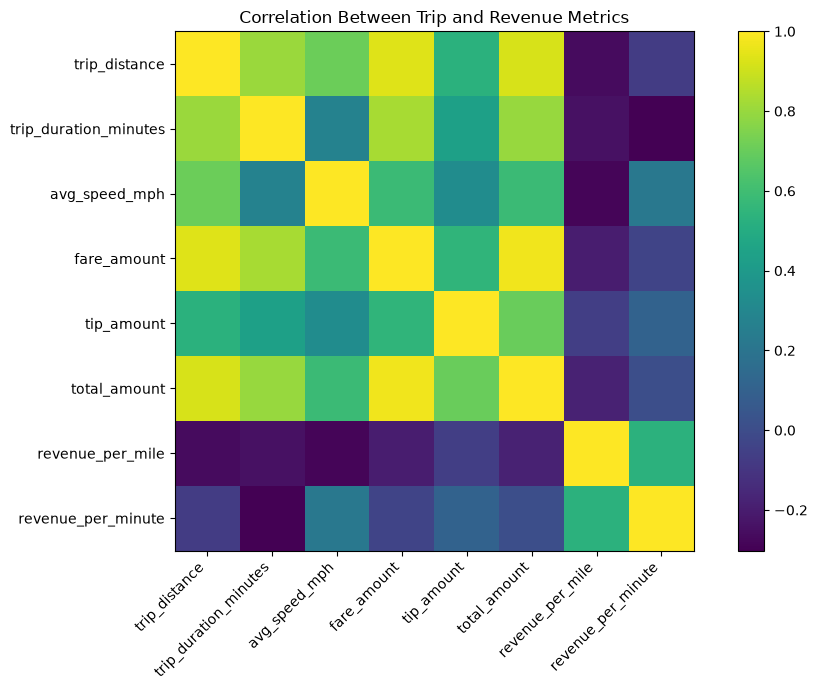

In [6]:
fig, ax = plt.subplots(
    figsize=(10, 7)
)

im = ax.imshow(
    correlation_matrix
)

ax.set_xticks(
    range(len(corr_columns))
)

ax.set_yticks(
    range(len(corr_columns))
)

ax.set_xticklabels(
    corr_columns,
    rotation=45,
    ha="right"
)

ax.set_yticklabels(
    corr_columns
)

fig.colorbar(
    im,
    ax=ax
)

plt.title(
    "Correlation Between Trip and Revenue Metrics"
)

plt.tight_layout()
plt.show()

In [9]:
from scipy.stats import ttest_ind

rush = analysis_df.loc[
    analysis_df["is_rush_hour"] == 1,
    "total_amount"
].dropna()

non_rush = analysis_df.loc[
    analysis_df["is_rush_hour"] == 0,
    "total_amount"
].dropna()

t_stat, p_value = ttest_ind(
    rush,
    non_rush,
    equal_var=False
)

print(f"Rush-hour observations: {len(rush):,}")
print(f"Non-rush observations: {len(non_rush):,}")

print(f"Rush-hour mean: ${rush.mean():.2f}")
print(f"Non-rush mean: ${non_rush.mean():.2f}")

print(f"Mean difference: ${rush.mean() - non_rush.mean():.2f}")
print(f"T-statistic: {t_stat:.3f}")
print(f"P-value: {p_value:.6g}")

Rush-hour observations: 164,661
Non-rush observations: 435,339
Rush-hour mean: $28.51
Non-rush mean: $27.90
Mean difference: $0.60
T-statistic: 9.992
P-value: 1.66295e-23


In [10]:
mean_diff = rush.mean() - non_rush.mean()

pooled_sd = np.sqrt(
    (
        rush.var()
        + non_rush.var()
    ) / 2
)

cohens_d = mean_diff / pooled_sd

print(f"Cohen's d: {cohens_d:.4f}")

Cohen's d: 0.0288


In [13]:
rush = analysis_df.loc[
    analysis_df["is_rush_hour"],
    "total_amount"
].dropna()

non_rush = analysis_df.loc[
    ~analysis_df["is_rush_hour"],
    "total_amount"
].dropna()

In [14]:
mean_diff = (
    rush.mean()
    - non_rush.mean()
)

pooled_sd = np.sqrt(
    (
        rush.var()
        + non_rush.var()
    ) / 2
)

cohens_d = (
    mean_diff
    / pooled_sd
)

print(
    f"Mean difference: ${mean_diff:.2f}"
)

print(
    f"Cohen's d: {cohens_d:.4f}"
)

Mean difference: $0.60
Cohen's d: 0.0288


In [15]:
weekend_summary = (
    analysis_df
    .groupby("is_weekend")
    .agg(
        trips=("total_amount", "size"),
        avg_revenue=("total_amount", "mean"),
        avg_distance=("trip_distance", "mean"),
        avg_duration=("trip_duration_minutes", "mean"),
        avg_speed=("avg_speed_mph", "mean")
    )
    .round(2)
)

weekend_summary

,trips,avg_revenue,avg_distance,avg_duration,avg_speed
is_weekend,,,,,
False,423412,28.41,3.34,16.62,10.75
True,176588,27.25,3.49,15.25,12.22


In [16]:
weekend = analysis_df.loc[
    analysis_df["is_weekend"],
    "total_amount"
].dropna()

weekday = analysis_df.loc[
    ~analysis_df["is_weekend"],
    "total_amount"
].dropna()

t_stat, p_value = ttest_ind(
    weekend,
    weekday,
    equal_var=False
)

print(
    f"Weekend mean: ${weekend.mean():.2f}"
)

print(
    f"Weekday mean: ${weekday.mean():.2f}"
)

print(
    f"P-value: {p_value:.6g}"
)

Weekend mean: $27.25
Weekday mean: $28.41
P-value: 6.92166e-89


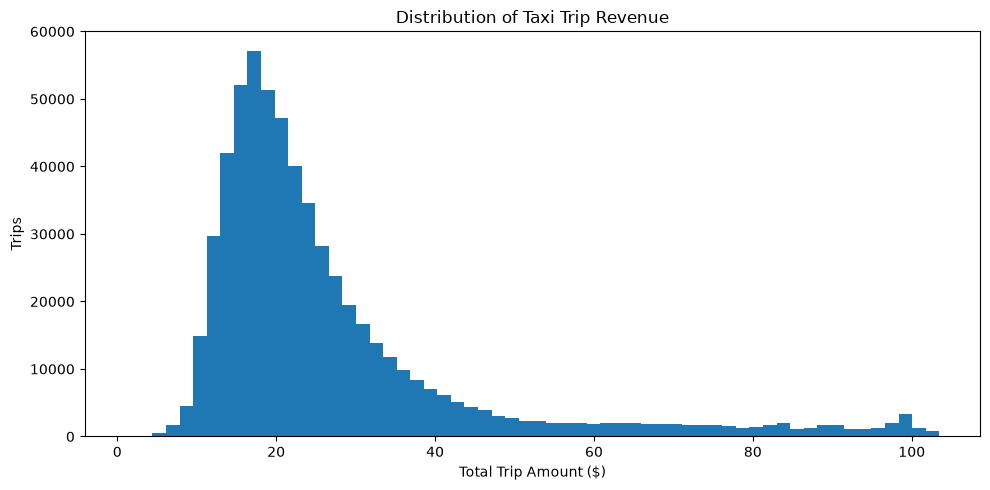

In [17]:
upper = analysis_df[
    "total_amount"
].quantile(.99)

plot_df = analysis_df[
    analysis_df["total_amount"] <= upper
]

plt.figure(
    figsize=(10, 5)
)

plt.hist(
    plot_df["total_amount"],
    bins=60
)

plt.xlabel(
    "Total Trip Amount ($)"
)

plt.ylabel(
    "Trips"
)

plt.title(
    "Distribution of Taxi Trip Revenue"
)

plt.tight_layout()
plt.show()

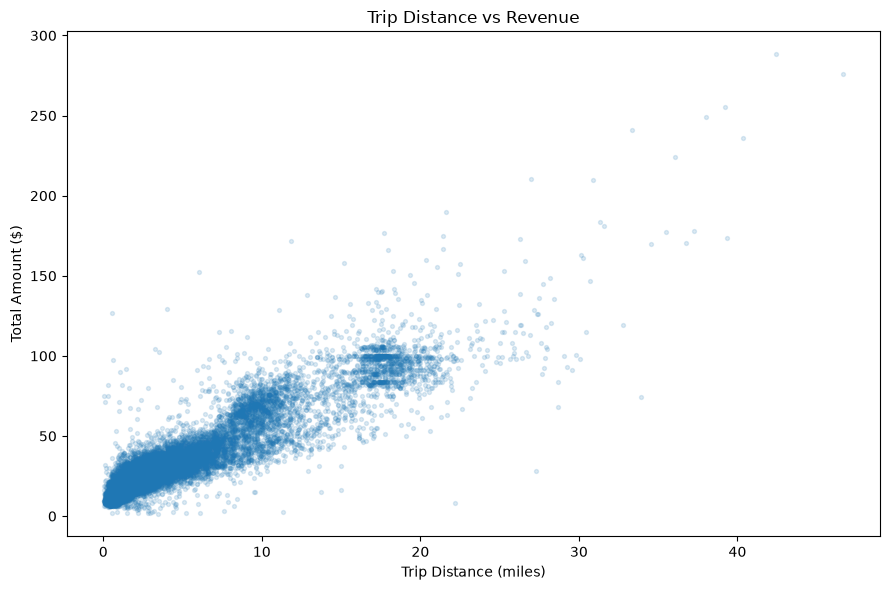

In [18]:
scatter_df = (
    analysis_df[
        [
            "trip_distance",
            "total_amount"
        ]
    ]
    .dropna()
    .sample(
        n=30_000,
        random_state=42
    )
)

plt.figure(
    figsize=(9, 6)
)

plt.scatter(
    scatter_df["trip_distance"],
    scatter_df["total_amount"],
    alpha=0.15,
    s=8
)

plt.xlabel(
    "Trip Distance (miles)"
)

plt.ylabel(
    "Total Amount ($)"
)

plt.title(
    "Trip Distance vs Revenue"
)

plt.tight_layout()
plt.show()

In [19]:
scatter_df = scatter_df[
    (scatter_df["trip_distance"] <= 30)
    & (scatter_df["total_amount"] <= 200)
]

In [20]:
hourly = (
    analysis_df
    .groupby("pickup_hour")
    .agg(
        trips=("total_amount", "size"),
        avg_revenue=("total_amount", "mean"),
        avg_speed=("avg_speed_mph", "mean")
    )
    .reset_index()
)

hourly

,pickup_hour,trips,avg_revenue,avg_speed
0,0,18682,28.564279,14.240941
1,1,12345,26.484104,14.224237
2,2,7962,24.791073,14.110777
3,3,5425,25.741871,15.434291
4,4,4068,31.439889,18.325969
5,5,4398,33.569065,19.027727
6,6,9043,29.786250,16.094150
7,7,17067,27.396025,12.777267
8,8,23473,26.362683,10.894824
9,9,24880,26.243479,10.680536


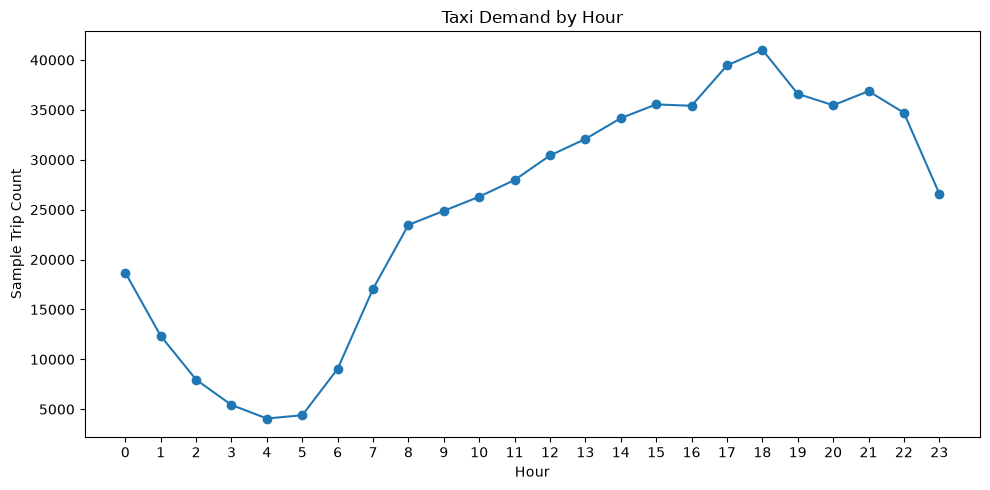

In [21]:
plt.figure(
    figsize=(10, 5)
)

plt.plot(
    hourly["pickup_hour"],
    hourly["trips"],
    marker="o"
)

plt.xticks(
    range(24)
)

plt.xlabel("Hour")
plt.ylabel("Sample Trip Count")

plt.title(
    "Taxi Demand by Hour"
)

plt.tight_layout()
plt.show()

In [22]:
airport_zones = [
    "JFK Airport",
    "LaGuardia Airport",
    "Newark Airport"
]

analysis_df["is_airport_pickup"] = (
    analysis_df["pickup_zone"]
    .isin(airport_zones)
)

airport_comparison = (
    analysis_df
    .groupby("is_airport_pickup")
    .agg(
        trips=("total_amount", "size"),
        avg_revenue=("total_amount", "mean"),
        avg_distance=("trip_distance", "mean"),
        avg_duration=("trip_duration_minutes", "mean"),
        avg_speed=("avg_speed_mph", "mean")
    )
    .round(2)
)

airport_comparison

,trips,avg_revenue,avg_distance,avg_duration,avg_speed
is_airport_pickup,,,,,
False,559299,24.51,2.66,14.63,10.34
True,40701,77.06,13.35,37.96,22.82


In [23]:
(
    analysis_df
    .groupby(
        [
            "payment_type",
            "pickup_borough"
        ]
    )
    .size()
    .sort_values(
        ascending=False
    )
    .head(20)
)

payment_type  pickup_borough
1             Manhattan         377809
0             Manhattan          86543
2             Manhattan          51956
1             Queens             36634
0             Brooklyn           13071
              Queens              8567
2             Queens              6898
4             Manhattan           5388
1             Brooklyn            3962
0             Bronx               2936
3             Manhattan           1661
4             Queens              1432
1             Bronx               1014
              Unknown             1003
2             Brooklyn             375
3             Queens               345
2             Unknown              150
              Bronx                 81
4             Brooklyn              47
0             Staten Island         43
dtype: int64

In [24]:
analysis_df[
    "payment_type"
].value_counts(
    dropna=False,
    normalize=True
)

payment_type
1    0.700712
0    0.185308
2    0.099110
4    0.011477
3    0.003393
Name: proportion, dtype: float64

In [ ]:
#save images

In [ ]:
# Key Statistical Findings
       # - Taxi demand shows strong temporal variation, with evening hours representing the highest-demand period.
       # - Rush-hour trips generate slightly higher average revenue than non-rush-hour trips, but the very small Cohen's d indicates that the practical effect of rush-hour status alone is limited.
       # - Weekday trips have higher average revenue than weekend trips in the analytical sample.
       # - Trip distance and duration are important factors associated with trip revenue, while operational efficiency metrics capture a different dimension of trip performance.
       # - Airport pickups represent a distinct economic segment, characterized by substantially longer trips and higher average trip values than non-airport pickups.
       # - Credit cards are the dominant recorded payment method, while a meaningful share of records have an unknown payment type and should be treated as a source-data limitation.

SyntaxError: unterminated string literal (detected at line 4) (3633440662.py, line 4)